# Case bootstrap of the final structure

The 22 conditions are the independent experimental units, so the bootstrap resamples **conditions** with replacement
(`bootstrap_n` resamples, seed `seed`) and refits the final structure on each resample, warm started at the final fit.
With `bootstrap_local_starts` > 0 each resample is also refitted from that many local starts (every free parameter at the
estimate times $10^{U(-s,\,s)}$ with $s$ = `bootstrap_local_span` decades, clipped to its bounds) and the best fit is
kept: a fit started only at the estimate stays near it where the objective is flat, which would make the intervals too
narrow.
A free parameter is **practically identifiable** if the ratio of the 97.5 and 2.5 percentiles of its estimates is at
most `bootstrap_ci_ratio`, the interval does not reach a parameter bound (within 1%), and the selection did not keep
it free by design. The objective of each resample is also
regressed on the number of copies of the two worst-fitted conditions (KO18, KO05). Code: `src/uncertainty/bootstrap.py`.

In [1]:
import os
import sys
import json
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)
from paths import resolve_out

OUT = resolve_out(os.environ.get("HK_OUT") or settings.METHOD["out_dir"])
RUN = os.environ.get("HK_RUN", "0") == "1"

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)
print("OUT :", OUT)
print("RUN :", RUN, "(False: load the saved results of OUT; True: compute and save into OUT)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

from uncertainty import bootstrap

FINAL = os.path.join(OUT, "final")
BOOT = os.path.join(OUT, "bootstrap")

OUT : /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model
RUN : False (False: load the saved results of OUT; True: compute and save into OUT)


In [2]:
# Settings of the method (defaults from settings/method.csv)
params = settings.default_params()
params["n_jobs"] = int(os.environ.get("HK_N_JOBS", params["n_jobs"]))
params

{'n_starts': 50,
 'seed': 0,
 'structural_q': 10,
 'structural_tol': 1e-10,
 'rank_tol': 0.0001,
 'corr_threshold': 0.9,
 'lr_alpha': 0.95,
 'bootstrap_n': 5000,
 'bootstrap_ci_ratio': 10.0,
 'bootstrap_local_starts': 5,
 'bootstrap_local_span': 1.0,
 'profile_points': 30,
 'profile_span': 1.0,
 'profile_extra_starts': 3,
 'profile_extra_span': 1.0,
 'bootstrap_profile_seeds': 3,
 'n_jobs': 10,
 'out_dir': 'results/flux_model'}

In [3]:
if RUN:
    bootstrap.run_bootstrap(FINAL, BOOT, params, resume=os.environ.get("HK_RESUME", "0") == "1")
else:
    print("RUN is False: the bootstrap is loaded from", BOOT)

RUN is False: the bootstrap is loaded from /Users/gabbi/Desktop/Repos/HybridKinetics-IIQ3733/results/flux_model/bootstrap


In [4]:
info = json.load(open(os.path.join(BOOT, "bootstrap_info.json")))
summary = pd.read_csv(os.path.join(BOOT, "bootstrap_summary.csv"), index_col=0)
print("%d/%d resamples converged" % (info["n_converged"], info["n_resamples"]))
print("objective: estimate %.3f, bootstrap median %.3f, 95%% [%.2f, %.2f]" % (
    info["obj_estimate"], info["obj_boot_median"], *info["obj_boot_p2.5_p97.5"]))
print("objective ~ %.2f + %.2f n_KO18 + %.2f n_KO05 (R2 %.2f)" % (
    info["obj_regression_intercept"], info["obj_per_KO18_copy"], info["obj_per_KO05_copy"], info["obj_regression_R2"]))
print("practically identifiable:", ", ".join(info["practically_identifiable"]) or "none")
summary.round(4)

5000/5000 resamples converged
objective: estimate 10.909, bootstrap median 10.289, 95% [2.67, 23.89]
objective ~ 3.53 + 6.01 n_KO18 + 1.14 n_KO05 (R2 0.98)
practically identifiable: kcat_f_4, kcat_f_6, kcat_f_8


,estimate,median,p2.5,p97.5,cv_percent,ci_ratio_97.5_over_2.5,interval_reaches_bound,kept_free_by_design,practically_identifiable,near_p2.5,near_p97.5,near_ci_ratio
param,,,,,,,,,,,,
v_max_1,80.2561,81.2406,72.2000,99.8284,7.5940,1.3827,True,False,False,66.7110,99.8594,1.4969
Ks_g6p_pgi,0.0050,0.0945,0.0010,3.7719,170.6090,3731.3802,False,False,False,0.0010,2.8670,2844.3126
kcat_f_2,978.1748,939.4030,461.4509,999.9063,18.4016,2.1669,True,False,False,511.8665,999.9023,1.9534
kcat_f_3,974.4076,972.2293,699.5945,999.9920,10.1140,1.4294,True,False,False,746.5158,999.9801,1.3395
Ks_fbp_4,0.0010,0.0010,0.0010,0.0010,1687.9734,1.0191,True,False,False,0.0010,0.0010,1.0109
kcat_f_4,2.6973,2.7081,2.4416,3.2592,630.4137,1.3349,False,False,True,2.4758,3.0894,1.2478
kcat_f_5,6865.9168,5699.1317,3970.3215,9901.3812,21.3825,2.4938,True,False,False,1894.2033,9999.1142,5.2788
kcat_f_6,622.6176,541.9315,192.4354,882.6783,21.4478,4.5869,False,False,True,145.8901,822.4368,5.6374
kcat_f_7,875.8411,772.0643,689.0333,999.7494,12.8994,1.4509,True,False,False,389.5088,999.8172,2.5669


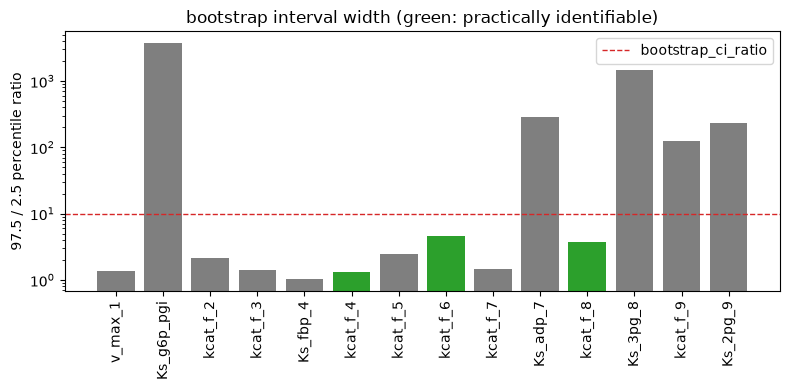

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(summary))
colors = ["tab:green" if flag else "tab:grey" for flag in summary["practically_identifiable"]]
ax.bar(x, summary["ci_ratio_97.5_over_2.5"], color=colors)
ax.axhline(params["bootstrap_ci_ratio"], color="tab:red", ls="--", lw=1, label="bootstrap_ci_ratio")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(summary.index, rotation=90)
ax.set_ylabel("97.5 / 2.5 percentile ratio")
ax.legend()
ax.set_title("bootstrap interval width (green: practically identifiable)")
fig.tight_layout()
plt.show()

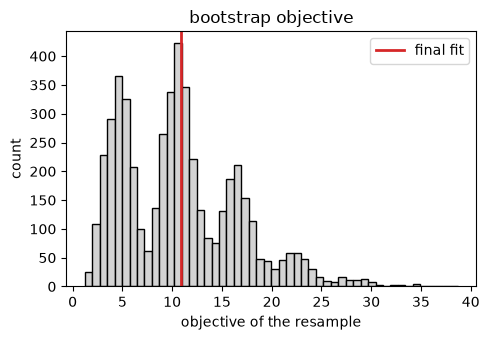

In [6]:
fits = pd.read_csv(os.path.join(BOOT, "bootstrap_theta.csv"))
fits = fits[fits["converged"]]
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.hist(fits["obj"], bins=50, color="lightgrey", edgecolor="black")
ax.axvline(info["obj_estimate"], color="tab:red", lw=2, label="final fit")
ax.set_xlabel("objective of the resample")
ax.set_ylabel("count")
ax.legend()
ax.set_title("bootstrap objective")
fig.tight_layout()
plt.show()